In [1]:
import subprocess
subprocess.run(['pip', 'install', 'scipy'])

CompletedProcess(args=['pip', 'install', 'scipy'], returncode=0)

In [5]:
import numpy as np
from scipy.stats import norm
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

def black_scholes(S, K, T, r, sigma, option_type='call'):
    """
    S: Current stock price
    K: Strike price
    T: Time to expiration (in years)
    r: Risk-free interest rate
    sigma: Volatility
    """
    d1 = (np.log(S/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)

    if option_type == 'call':
        price = S*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)
    else:
        price = K*np.exp(-r*T)*norm.cdf(-d2) - S*norm.cdf(-d1)

    return price

print("Black-Scholes function ready!")

Black-Scholes function ready!


In [7]:
# Use Apple as the underlying stock
ticker = 'AAPL'
stock = yf.Ticker(ticker)

# Get current stock price
current_price = stock.history(period='1d')['Close'].iloc[-1]
print(f"Current {ticker} Price: ${current_price:.2f}")

# Get historical data for volatility calculation
hist = stock.history(start='2023-01-01', end='2024-01-01')
returns = hist['Close'].pct_change().dropna()

# Calculate annualized volatility
volatility = returns.std() * np.sqrt(252)
print(f"Annualized Volatility: {volatility:.4f} ({volatility*100:.2f}%")

Current AAPL Price: $333.74
Annualized Volatility: 0.1995 (19.95%


In [8]:
# Black-Scholes inputs
S = current_price          # Current stock price
K = round(current_price)   # At-the-money strike price
T = 0.25                   # 3 months to expiration
r = 0.05                   # Risk-free rate (5%)
sigma = volatility          # Historical volatility

call_price = black_scholes(S, K, T, r, sigma, 'call')
put_price = black_scholes(S, K, T, r, sigma, 'put')

print(f"\nBlack-Scholes Option Pricing for {ticker}")
print(f"Stock Price: ${S:.2f}")
print(f"Strike Price: ${K:.2f}")
print(f"Time to Expiration: {T} years")
print(f"Risk-Free Rate: {r*100}%")
print(f"Volatility: {sigma*100:.2f}%")
print(f"\nCall Option Price: ${call_price:.2f}")
print(f"Put Option Price: ${put_price:.2f}")


Black-Scholes Option Pricing for AAPL
Stock Price: $333.74
Strike Price: $334.00
Time to Expiration: 0.25 years
Risk-Free Rate: 5.0%
Volatility: 19.95%

Call Option Price: $15.24
Put Option Price: $11.35


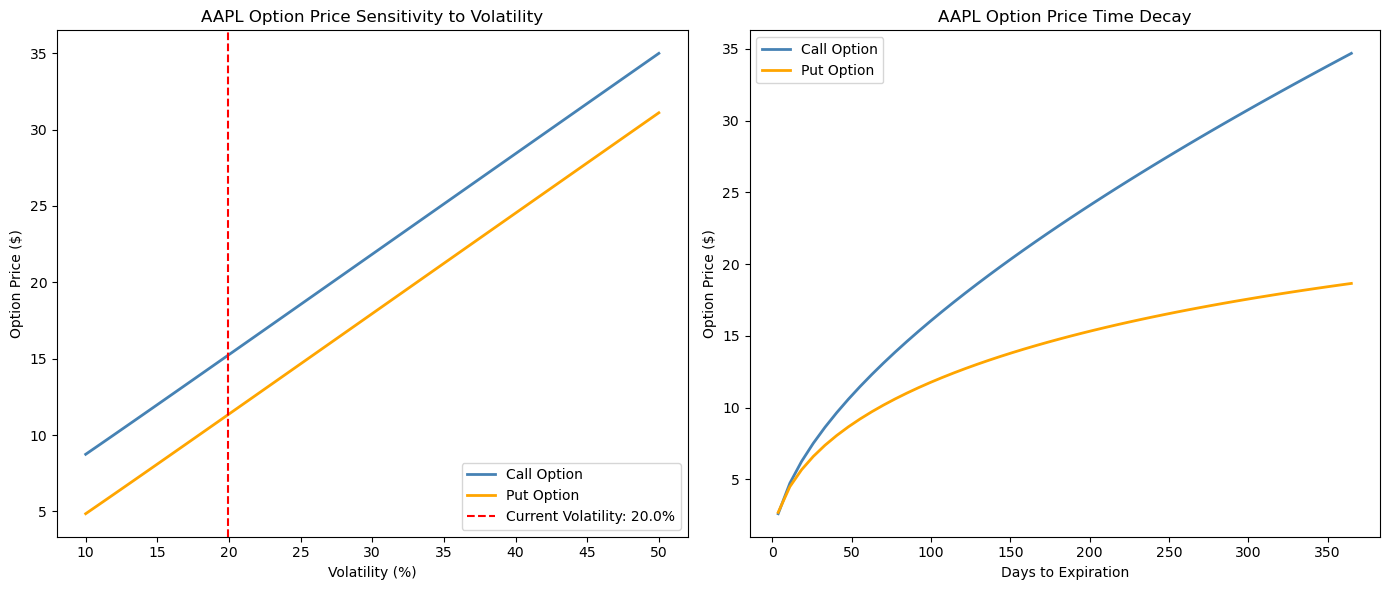

Charts saved!


In [10]:
# Sensitivity Analysis: How option price changes with volatility
volatilities = np.linspace(0.10, 0.50, 50)
call_prices = [black_scholes(S, K, T, r, v, 'call') for v in volatilities]
put_prices = [black_scholes(S, K, T, r, v, 'put') for v in volatilities]

# Sensitivity Analysis: How option price changes with time to expiration
times = np.linspace(0.01, 1, 50)
call_prices_time = [black_scholes(S, K, t, r, sigma, 'call') for t in times]
put_prices_time = [black_scholes(S, K, t, r, sigma, 'put') for t in times]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Chart 1 - Volatility sensitivity
axes[0].plot(volatilities*100, call_prices, label='Call Option', color='steelblue', linewidth=2)
axes[0].plot(volatilities*100, put_prices, label='Put Option', color='orange', linewidth=2)
axes[0].axvline(sigma*100, color='red', linestyle='--', label=f'Current Volatility: {sigma*100:.1f}%')
axes[0].set_xlabel('Volatility (%)')
axes[0].set_ylabel('Option Price ($)')
axes[0].set_title(f'{ticker} Option Price Sensitivity to Volatility')
axes[0].legend()

# Chart 2 - Time decay
axes[1].plot(times*365, call_prices_time, label='Call Option', color='steelblue', linewidth=2)
axes[1].plot(times*365, put_prices_time, label='Put Option', color='orange', linewidth=2)
axes[1].set_xlabel('Days to Expiration')
axes[1].set_ylabel('Option Price ($)')
axes[1].set_title(f'{ticker} Option Price Time Decay')
axes[1].legend()

plt.tight_layout()
plt.savefig('option_pricing_sensitivity.png', dpi=300)
plt.show()
print("Charts saved!")

In [11]:
def calculate_greeks(S, K, T, r, sigma, option_type='call'):
    d1 = (np.log(S/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    
    # Delta - price sensitivity to underlying stock price
    if option_type == 'call':
        delta = norm.cdf(d1)
    else:
        delta = norm.cdf(d1) - 1
    
    # Gamma - rate of change of delta
    gamma = norm.pdf(d1) / (S * sigma * np.sqrt(T))
    
    # Vega - sensitivity to volatility
    vega = S * norm.pdf(d1) * np.sqrt(T) / 100
    
    # Theta - time decay
    if option_type == 'call':
        theta = (-S*norm.pdf(d1)*sigma/(2*np.sqrt(T)) - 
                 r*K*np.exp(-r*T)*norm.cdf(d2)) / 365
    else:
        theta = (-S*norm.pdf(d1)*sigma/(2*np.sqrt(T)) + 
                 r*K*np.exp(-r*T)*norm.cdf(-d2)) / 365
    
    # Rho - sensitivity to interest rate
    if option_type == 'call':
        rho = K*T*np.exp(-r*T)*norm.cdf(d2) / 100
    else:
        rho = -K*T*np.exp(-r*T)*norm.cdf(-d2) / 100
    
    return {
        'Delta': delta,
        'Gamma': gamma,
        'Vega': vega,
        'Theta': theta,
        'Rho': rho
    }

call_greeks = calculate_greeks(S, K, T, r, sigma, 'call')
put_greeks = calculate_greeks(S, K, T, r, sigma, 'put')

print("CALL OPTION GREEKS")
for greek, value in call_greeks.items():
    print(f"{greek}: {value:.4f}")

print("\nPUT OPTION GREEKS")
for greek, value in put_greeks.items():
    print(f"{greek}: {value:.4f}")

CALL OPTION GREEKS
Delta: 0.5665
Gamma: 0.0118
Vega: 0.6565
Theta: -0.0956
Rho: 0.4345

PUT OPTION GREEKS
Delta: -0.4335
Gamma: 0.0118
Vega: 0.6565
Theta: -0.0504
Rho: -0.3901


In [12]:
results_df = pd.DataFrame({
    'Metric': ['Stock Price', 'Strike Price', 'Time to Expiration', 
               'Risk-Free Rate', 'Volatility', 'Call Price', 'Put Price'],
    'Value': [S, K, T, r, sigma, call_price, put_price]
})

greeks_df = pd.DataFrame({
    'Greek': ['Delta', 'Gamma', 'Vega', 'Theta', 'Rho'],
    'Call Option': list(call_greeks.values()),
    'Put Option': list(put_greeks.values())
})

with pd.ExcelWriter('option_pricing_results.xlsx') as writer:
    results_df.to_excel(writer, sheet_name='Option Pricing', index=False)
    greeks_df.to_excel(writer, sheet_name='Greeks', index=False)

print("Results saved to option_pricing_results.xlsx")
print("Project 4 Core Complete!")

Results saved to option_pricing_results.xlsx
Project 4 Core Complete!
